# Momompurin Online Ordering and Inventory Management System — Algorithm Benchmarking

**ALGOCOM Final Requirement (Revised Benchmarking Analysis) · Group 8 · III-BCSAD · University of Makati**

Prof. Nomar B. Maestro · 22 November 2026 · **v3**, rebuilt against the
*Notebook Map & Technical Validation* review and re-synced with the shipped **v2.3** app

---

## What changed since the first consult, and why this notebook measures what it measures

The first version of this analysis described the matching engine as part of a **live-comment
workflow**: the owner types what a buyer claimed in a Facebook Live comment and the app resolves
it to a SKU. That was the workflow in the concept paper.

After **client and SOFTENG validation**, order entry pivoted to a **two-sided self-service app** —
`Customer Shop`, where buyers order for themselves, and `Owner Stock`, where the owner manages the
catalogue. The typo problem did not disappear with the pivot; it moved. What used to arrive as a
typed live claim now arrives as **typed search text on both sides**:

| Surface | Who types | What they type | What must happen |
|---|---|---|---|
| **A-13 · Customer Shop Search** | buyer | `chikwa wips`, `meldy pouch` | resolve to the right card, so the buyer orders the item they meant |
| **A-03 · Owner Stock Search** | owner | `sanrio wach`, `kuromy scrub` | resolve to the right row, so stock is decremented on the SKU that actually left |

**The identical matching engine runs in both.** `TrigramProductMatcher` — the Kotlin port of
`algorithms/inverted_index.py` — is the live fallback stage of `SearchPipeline`
(`app/src/main/java/ph/edu/umak/momompurin/data/SearchPipeline.kt`), called from `ShopScreen.kt`
(A-13) and `StockScreen.kt` (A-03). Its behaviour is pinned by
`V23SprintTest.algocom_trigram_matcher_ranks_the_typo_top`, which asserts that `"chikwa wips"`
ranks `CHW · Chiikawa Wipes` first against the real catalogue.

So this notebook still benchmarks **the matching engine on Katrina's real 767-item catalogue**,
because that engine is the one component whose behaviour on messy human text decides whether the
shop sells stock it does not have — and because the pivot doubled its exposure rather than
retiring it. Filipino shopper shorthand (`po`, `mine`, `sakin`) and dropped words are the inputs
the pivot introduced; character typo tolerance alone would not cover them.

### Scope after the consultation, unchanged

- The matching engine is **kept and defended**: it is an optimisation, not a place for machine
  learning. Training data does not exist for a three-month-old shop, and a model that is wrong 3%
  of the time with no explanation is harder to operate mid-stream than a scoring function the
  owner can read.
- **Prefix Trie and FSM remain implemented in the v2.3 app** and are **excluded as benchmark
  subjects** per the consultation. The Min-Heap remains in the Python reference repository but a
  Kotlin v2.3 implementation was not found, so this notebook does not claim it ships in the APK.
  These scope distinctions are recorded in `docs/ALGORITHM_CHECKLIST.md`.
- **What is measured here**: the matching engine (§3, §4, §4b) and one algorithmic feature the
  workflow needs — courier tracking-number validation (§5).

> **Note on absolute numbers.** Wall-clock times depend on the machine. Run this in Colab and the
> milliseconds will differ from the report, which ran on the group's own hardware. The **ratios**
> and the **accuracy figures** are what the argument rests on, and those are stable across
> machines.

## Input → output: what "matching" actually does

Three real queries against the real catalogue, with the numbers this notebook's code produces.

**A doubled-character typo** — `chikwa` for `chiikawa`:

```
in   "chikwa wips"
     norm()          -> "chikwa wips"                         (unchanged)
     trigrams()      -> 13 grams: {"  c"," ch","chi","hik","ikw","kwa","wa ",
                                   "a w"," wi","wip","ips","ps ","s  "}
     index union     -> 214 of 767 rows survive   (72.1% pruned)
     Jaccard         -> CHW "Chiikawa Wipes" 0.3810
                        next best (MWF "Miffy Wipes") 0.1304
out  CHW · Chiikawa Wipes        <- the assertion in V23SprintTest, reproduced here
```

**A Filipino shopper's shorthand** — the pivot's new input class:

```
in   "meldy pouch"                 ("meldy" = Melody, "pouch" = the category)
     index union     -> 329 of 767 rows survive   (57.1% pruned)
     Jaccard         -> MSPP "Melo Piano Japan Kuji Pouch" 0.2727
                        next best (ST8 "Melody Pen Cap") 0.2083
out  MSPP · Melo Piano Japan Kuji Pouch
```

**Where the score gets thin** — a two-letter token is the honest failure case:

```
in   "po"                          (politeness particle, not a product word)
     trigrams()      -> 4 grams only
     index union     -> 200 of 767 rows survive   (73.9% pruned)
     Jaccard         -> a TWO-WAY TIE at 0.1429 (MS2 "Pom Mascot",
                        PC1M "Pochacco 120p Memo"); P1M is next at 0.1364
out  whatever the tie-break picks  <- sorted(pool) makes that choice deterministic,
                                       it does not make it correct
```

The third example is the point. The engine is not magic; it is a **pruning rule plus a score**,
and its failures concentrate in short queries and dropped words. §3.1 lists the misses instead of
asserting them away.

### The pipeline, end to end

```
  raw query          "chikwa wips"
      |
      v
  norm()             lowercase, "&" -> " and ", punctuation -> space, collapse whitespace
      |              "chikwa wips"
      v
  trigrams()         pad two spaces each side, take every 3-char window
      |              13 grams
      v
  Inverted Index     postings lists: trigram -> [row ids containing it]
    Union            UNION, never intersect  (an intersection drops the right answer
      |              whenever only one gram is shared)
      v              214 candidates (~72% pruned)
  Sorted Candidate   for i in sorted(pool):
    Pool             sorted, so a score tie breaks identically to the full scan
      |
      v
  Jaccard Scoring    |A n B| / |A u B|, candidates only
      |
      v
  Top-K Ranked       [(CHW, 0.3810), (MWF, 0.1304), ...]
    Matches
```

Two rules in that diagram are load-bearing and argued in §3: the pool is **unioned** and iterated
**sorted**. Drop either and the benchmark's central assertion — that the index never changes an
answer — stops holding.

## 0 · Setup and data loading

Loads `catalogue.csv` — the client's real 767-row export — straight from the project's public
repository. The Colab URL is the default so **Runtime → Run all** works with no upload step; a
local copy is used automatically only if the network is unavailable.

This cell answers three questions a reviewer must be able to check without leaving the notebook:
what interpreter is running, whether any row is missing a name, and what the two duplicate SKUs
actually are.

### Engineering rationale — why an in-memory index at all

The catalogue is small (767 rows), so a full scan is not *slow* in absolute terms. The reason the
shipped app still builds an index is the shape of the workload, not the size of the data:

- **Search runs per keystroke, on a phone.** A-13 and A-03 re-filter on every character the buyer
  or owner types. The warmed full-scan and indexed latencies are measured in §3 on the Python
  reference; those timings motivate the trade-off but are not presented as device timings.
- **The index trades RAM for less work on each keystroke.** It is built once when the product list
  loads (`remember(data.products) { SearchPipeline.build(data) }`) and reused for subsequent
  searches; a linear scan would avoid the postings structure but score every row on each search.
- **Memory is measured, not assumed to be tiny.** §3 uses `tracemalloc` to print actual allocations
  for the Python reference's postings index and catalogue trigram sets. That is not a measurement of
  Kotlin heap usage on a phone; it gives a reproducible reference cost, while device-side memory
  still needs profiling if the catalogue grows.
- **The index does not replace scoring, it prunes.** So the win is whatever fraction of the
  catalogue the postings lists exclude — §3 measures it on this catalogue rather than assuming an
  order of magnitude. That is why the report quotes a measured ratio and its pruning rate together:
  the ratio is only as good as the pruning, and the pruning depends on how much text neighbouring
  product names share.

In [1]:
import csv
import platform
import re
import statistics
import sys
import time
import tracemalloc
import urllib.error
import urllib.request
from collections import Counter, defaultdict
from pathlib import Path

import pandas as pd

T0 = time.perf_counter()   # notebook wall-clock, reported in §6
MARKS = {}
RUN_ALL_BUDGET = 180.0     # seconds; a comfortable Colab run-all ceiling


def mark(label):
    """Record the wall-clock at the end of a section, for §6."""
    MARKS[label] = time.perf_counter() - T0


pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 40)

# ------------------------------------------------------------ environment
import matplotlib
import matplotlib.pyplot as plt
import numpy as np

print("interpreter      :", sys.version.split()[0], f"({platform.python_implementation()})")
print("pandas           :", pd.__version__)
print("numpy            :", np.__version__)
print("matplotlib       :", matplotlib.__version__)
print("platform         :", platform.platform())

# ------------------------------------------------------------ load
CATALOGUE_URL = (
    "https://raw.githubusercontent.com/WhiteQilin/"
    "momompurin-live-manager/main/algorithms/benchmark/catalogue.csv"
)
LOCAL_CANDIDATES = [
    Path("algorithms/benchmark/catalogue.csv"),
    Path("notebooks/algorithms/benchmark/catalogue.csv"),
    Path("../algorithms/benchmark/catalogue.csv"),
    Path("momompurin-live-manager/algorithms/benchmark/catalogue.csv"),
    Path("../momompurin-live-manager/algorithms/benchmark/catalogue.csv"),
    Path("../../momompurin-live-manager/algorithms/benchmark/catalogue.csv"),
    Path("/content/catalogue.csv"),
]

try:
    with urllib.request.urlopen(CATALOGUE_URL, timeout=30) as r:
        rows = list(csv.DictReader(r.read().decode("utf-8").splitlines()))
    SOURCE = "GitHub (public repository) - no upload step"
except (urllib.error.URLError, TimeoutError, OSError) as exc:
    print()
    print(f"network unavailable ({type(exc).__name__}) - trying a local copy")
    for cand in LOCAL_CANDIDATES:
        if cand.exists():
            with cand.open(encoding="utf-8", newline="") as fh:
                rows = list(csv.DictReader(fh))
            SOURCE = f"local file: {cand}"
            break
    else:
        raise RuntimeError(
            "catalogue.csv could not be loaded from the repository or from any local path "
            f"in {[str(p) for p in LOCAL_CANDIDATES]}"
        ) from exc

SKUS = [row["sku"] for row in rows]
NAMES = [row["item_name"] for row in rows]

print()
print("catalogue source :", SOURCE)
print("catalogue rows   :", len(rows))
print("distinct SKUs    :", len(set(SKUS)))
print()
print("first five entries:")
for sku, name in list(zip(SKUS, NAMES))[:5]:
    print(f"  {sku:<10} {name}")

# ------------------------------------------------------------ missing names
missing_name = [i for i, n in enumerate(NAMES) if not str(n).strip()]
assert not missing_name, f"{len(missing_name)} row(s) have an empty item_name: {missing_name[:10]}"
print()
print(f"rows with an empty/blank item_name : {len(missing_name)}   (asserted to be 0)")

# ------------------------------------------------------------ the duplicate SKUs
sku_counts = Counter(SKUS)
dup_skus = sorted(s for s in sku_counts if sku_counts[s] > 1)

dup_frame = pd.DataFrame([
    {"sku": s, "catalogue row": i, "item_name": NAMES[i]}
    for s in dup_skus for i, sku in enumerate(SKUS) if sku == s
])
dup_names_differ = all(
    dup_frame.loc[dup_frame["sku"] == s, "item_name"].nunique() > 1 for s in dup_skus
)

print()
print(f"duplicate SKUs : {len(dup_skus)} SKU(s) over {len(dup_frame)} rows "
      f"({len(rows)} rows vs {len(set(SKUS))} distinct SKUs)")
print(dup_frame.to_string(index=False))
print()
print("do the duplicated SKUs collide on item name?  ",
      "NO - each carries a DIFFERENT name" if dup_names_differ else "YES - names repeat")
print()
print("FINDING: both duplicate SKUs name different products, so each row is a genuinely")
print("         distinct product sharing a code. Every engine below therefore sees two")
print("         separate catalogue rows and no query can score against the wrong text.")
print("         (Duplicate NAMES are a separate issue - measured next.)")

# ------------------------------------------------------------ duplicate NAMES
def _norm_only(s):
    s = str(s).lower().replace("&", " and ")
    s = re.sub(r"[^a-z0-9 ]+", " ", s)
    return re.sub(r"\s+", " ", s).strip()


name_groups = defaultdict(list)
for i, n in enumerate(NAMES):
    name_groups[_norm_only(n)].append(i)
shared_names = {n: v for n, v in name_groups.items() if len(v) > 1}

print()
print(f"normalised item_names shared by more than one row : {len(shared_names)} name(s) "
      f"across {sum(len(v) for v in shared_names.values())} rows")
for n, idxs in sorted(shared_names.items()):
    print(f"   {n!r}")
    for i in idxs:
        print(f"       row {i:>3}  {SKUS[i]:<8} {NAMES[i]}")
print()
print("This matters for scoring: a query derived from the SECOND copy of an identical")
print("name cannot be scored as a hit - both rows carry the same text. Section 3.2")
print("quantifies how many queries are affected instead of leaving it implicit.")

mark("0 · setup")

interpreter      : 3.14.5 (CPython)
pandas           : 3.0.5
numpy            : 2.5.0
matplotlib       : 3.11.2
platform         : Windows-11-10.0.26200-SP0



catalogue source : GitHub (public repository) - no upload step
catalogue rows   : 767
distinct SKUs    : 765

first five entries:
  W1         Hangyodon Wipes
  T1         Hangyodon Tissue
  W2         HK mini wipes 8pcs Blue
  W3         Cinna mini wipes 8pcs
  HKW1       HK mini wipes 8pcs Red

rows with an empty/blank item_name : 0   (asserted to be 0)

duplicate SKUs : 2 SKU(s) over 4 rows (767 rows vs 765 distinct SKUs)
sku  catalogue row           item_name
MS2             38          Pom Mascot
MS2             99 Melody Mini Storage
SC1             54   Cinnamoroll Scrub
SC1             77  Kuromi Body Scrubs

do the duplicated SKUs collide on item name?   NO - each carries a DIFFERENT name

FINDING: both duplicate SKUs name different products, so each row is a genuinely
         distinct product sharing a code. Every engine below therefore sees two
         separate catalogue rows and no query can score against the wrong text.
         (Duplicate NAMES are a separate issue - m

## 1 · Shared helpers

Normalisation, trigram extraction, Jaccard similarity, and a best-of-N timing helper. These are the
same functions the shipped implementation uses — `algorithms/inverted_index.py`, ported to Kotlin
as `TrigramText` in `TrigramProductMatcher.kt`. That Kotlin file pins three rules that change
results if dropped (union not intersection, sorted pool, strict `>` on ties); all three are carried
here so the measured numbers describe the shipped behaviour.

The unused `SKU_NORM` of the earlier revision is gone — it was computed once and never read.

In [2]:
def norm(s: str) -> str:
    """Lowercase, expand '&', strip punctuation, collapse whitespace."""
    s = str(s).lower().replace("&", " and ")
    s = re.sub(r"[^a-z0-9 ]+", " ", s)
    return re.sub(r"\s+", " ", s).strip()


def trigrams(s: str):
    """Character trigrams of the padded string, as a frozenset.

    The two-space pad on each side gives the first and last characters order-two
    context, so "chw" and "chi" share the "  c" family of grams rather than nothing.
    A frozenset (not a set) so scores cannot depend on iteration order.
    """
    p = f"  {s}  "
    return frozenset(p[i:i + 3] for i in range(len(p) - 2))


def jaccard(a, b) -> float:
    """|A n B| / |A u B| over trigram sets. Empty/empty scores 0, not 1."""
    if not a and not b:
        return 0.0
    inter = len(a & b)
    return inter / (len(a) + len(b) - inter)


REPEATS = 3      # best-of-3, after a warm-up pass


def timed(fn, repeats: int = REPEATS):
    """Best-of-N wall clock in milliseconds, plus the function's return value."""
    best = float("inf")
    result = None
    for _ in range(repeats):
        t0 = time.perf_counter()
        result = fn()
        best = min(best, time.perf_counter() - t0)
    return best * 1000.0, result


NAME_NORM = [norm(n) for n in NAMES]
CAT_TRI = [trigrams(n) for n in NAME_NORM]

print("helpers ready")
print(f"catalogue trigram sets built for {len(CAT_TRI)} items")
print(f"timing convention: best of {REPEATS} repeats, after a 50-query warm-up pass")

helpers ready
catalogue trigram sets built for 767 items
timing convention: best of 3 repeats, after a 50-query warm-up pass


### 1.1 · Edge-case unit tests for the three helpers

The helpers are the whole engine underneath: if `norm`, `trigrams` or `jaccard` misbehave on an
empty string or an ampersand, every number downstream is wrong for that input class. These are
asserted rather than eyeballed, and the pass count printed below is counted, not typed.

In [3]:
PASSED = 0


def check(condition, message):
    """Assert, and count the assertions that actually ran."""
    global PASSED
    assert condition, message
    PASSED += 1


# --- norm ---------------------------------------------------------------
check(norm("") == "", "empty string normalises to empty")
check(norm("   ") == "", "whitespace-only normalises to empty")
check(norm("A & B") == "a and b", f"'A & B' must expand: {norm('A & B')!r}")
check(norm("Melo Piano scrub") == "melo piano scrub", "already-clean name survives")
check(norm("Kuromi Body Scrubs!!") == "kuromi body scrubs", "punctuation becomes space")
check(norm("HK  mini   wipes") == "hk mini wipes", "whitespace runs collapse")
check(norm("J&T-76123456789") == "j and t 76123456789", norm("J&T-76123456789"))
check(norm("chikwa wips") == "chikwa wips", "typo query passes through unchanged")

# --- trigrams -----------------------------------------------------------
# An empty string still yields the single all-space gram from the pad. That is
# deliberate: it means no string, not even "", produces an empty set by accident.
check(trigrams("") == frozenset({"   "}), f"{trigrams('')!r}")
check(len(trigrams("a")) == 3, f"1-char string yields 3 grams, got {len(trigrams('a'))}")
check(len(trigrams("ab")) == 4, f"2-char string yields 4 grams, got {len(trigrams('ab'))}")
check(len(trigrams("abc")) == 5, "3-char string yields 5 grams (4 pad chars + 1 unpad)")
check(len(trigrams("chikwa wips")) == 13, len(trigrams("chikwa wips")))
check("  c" in trigrams("chw"), "padding gives the leading-char gram")
check(trigrams("abc") == trigrams("abc"), "deterministic")

# --- jaccard ------------------------------------------------------------
identical = trigrams("cinnamoroll")
check(jaccard(identical, identical) == 1.0, "identical sets score exactly 1.0")
check(jaccard(trigrams("abc"), trigrams("xyz")) == 0.0, "disjoint strings score 0.0")
check(jaccard(frozenset(), frozenset()) == 0.0, "empty/empty is 0, never 1")
check(jaccard(frozenset(), identical) == 0.0, "empty vs non-empty is 0")
check(0.0 < jaccard(trigrams("cinnamoroll"), trigrams("cinnamorol")) < 1.0, "one typo < 1")
check(jaccard(trigrams("chikwa wips"), trigrams("chiikawa wipes")) > 0.0, "typo still scores")
check(
    jaccard(trigrams("chikwa wips"), trigrams("chiikawa wipes"))
    == jaccard(trigrams("chiikawa wipes"), trigrams("chikwa wips")),
    "symmetric in argument order",
)
check(jaccard(identical, identical) <= 1.0 and jaccard(identical, identical) >= 0.0, "bounded")

print(f"helper unit tests : {PASSED} assertions passed")
print()
print("  norm('A & B')                 ->", repr(norm("A & B")))
print("  norm('Kuromi Body Scrubs!!')  ->", repr(norm("Kuromi Body Scrubs!!")))
print("  len(trigrams('a'))            ->", len(trigrams("a")), "(padded, never empty)")
print("  len(trigrams('chikwa wips'))  ->", len(trigrams("chikwa wips")), "grams")
print("  jaccard(x, x)                 ->", jaccard(identical, identical))
print("  jaccard('abc', 'xyz')         ->", jaccard(trigrams("abc"), trigrams("xyz")))
print("  jaccard('', '')               ->", jaccard(frozenset(), frozenset()))

mark("1 · helpers")

helper unit tests : 23 assertions passed

  norm('A & B')                 -> 'a and b'
  norm('Kuromi Body Scrubs!!')  -> 'kuromi body scrubs'
  len(trigrams('a'))            -> 3 (padded, never empty)
  len(trigrams('chikwa wips'))  -> 13 grams
  jaccard(x, x)                 -> 1.0
  jaccard('abc', 'xyz')         -> 0.0
  jaccard('', '')               -> 0.0


## 2 · The query set

The workbook's `LiveClaims` sheet stores the **resolved SKU**, not the raw comment, so a replay of
real typed text is not possible from the data. The query set is therefore built by perturbing real
catalogue names the way buyers and owners actually type them, under a fixed seed so a re-run is
comparable.

| Perturbation | Target weight | Example |
|---|---|---|
| 1 typo (delete, swap, substitute, duplicate a character) | 46% | `cinnamoroll` → `cinamoroll` |
| 2 typos | 18% | |
| Dropped word | 18% | `my melody pouch purple` → `my melody purple` |
| Pasted chat noise | 18% | `po claim`, `mine`, `sakin` |

Each query carries its **true answer** — the row index it was derived from — so top-1 accuracy is
measurable rather than asserted. The cell below prints the realised split against the target, so
the random draw is verified rather than trusted.

In [4]:
import random


def perturb(name: str, rng):
    """A typed variant of a catalogue name, plus the kind of error introduced."""
    s = norm(name)
    kind = rng.choices(["one", "two", "drop", "noise"], weights=[46, 18, 18, 18])[0]

    if kind == "noise":
        noise = rng.choice(["po", "claim", "ako", "mine", "sakin"])
        joined = f"{noise} {s}" if rng.random() < 0.5 else f"{s} {noise}"
        return norm(joined), "chat noise"

    if kind == "drop":
        words = s.split()
        if len(words) > 2:
            del words[rng.randrange(len(words))]
            return " ".join(words), "dropped word"
        kind = "one"          # too short to drop a word from - falls back to a typo

    edits = 1 if kind == "one" else 2
    chars = list(s)
    for _ in range(edits):
        if not chars:
            break
        op = rng.choice(["del", "swap", "sub", "dup"])
        i = rng.randrange(len(chars))
        if op == "del" and len(chars) > 4:
            del chars[i]
        elif op == "swap" and i + 1 < len(chars):
            chars[i], chars[i + 1] = chars[i + 1], chars[i]
        elif op == "sub":
            chars[i] = rng.choice("abcdefghijklmnopqrstuvwxyz")
        elif op == "dup":
            chars.insert(i, chars[i])
    out = "".join(chars)
    return (out if out != s else s + "x"), ("1 typo" if kind == "one" else "2 typos")


SEED = 20261104
rng = random.Random(SEED)

QUERIES, KINDS = [], []
for i, n in enumerate(NAMES):
    q, kind = perturb(n, rng)
    if q != NAME_NORM[i]:
        QUERIES.append((q, i))
        KINDS.append(kind)

# Build each query's trigram set once. The full-scan comparison can then isolate
# catalogue scoring rather than re-tokenizing the same query once per row.
QUERY_TRI = [trigrams(q) for q, _ in QUERIES]
QUERY_TRI_BY_TEXT = {q: tri for (q, _), tri in zip(QUERIES, QUERY_TRI)}


def query_trigrams(q):
    """Reuse the precomputed set when q belongs to the benchmark query set."""
    cached = QUERY_TRI_BY_TEXT.get(q)
    return cached if cached is not None else trigrams(q)


print(f"seed              : {SEED}")
print(f"catalogue rows    : {len(NAMES)}")
print(f"queries generated : {len(QUERIES)}")
print()

# --------------------------------------------- realised vs target breakdown
TARGET = {"1 typo": 46.0, "2 typos": 18.0, "dropped word": 18.0, "chat noise": 18.0}
order = ["1 typo", "2 typos", "dropped word", "chat noise"]
realised = Counter(KINDS)
breakdown = pd.DataFrame([
    {"error type": k,
     "queries": realised[k],
     "actual %": round(100 * realised[k] / len(QUERIES), 1),
     "target %": TARGET[k],
     "delta (pp)": round(100 * realised[k] / len(QUERIES) - TARGET[k], 1)}
    for k in order
])
print("realised perturbation mix vs the 46 / 18 / 18 / 18 target:")
print(breakdown.to_string(index=False))
print(f"{'TOTAL':<13}{len(QUERIES):>8}{100.0:>10.1f}")

draws = sum(realised.values())
chi = sum((realised[k] - draws * TARGET[k] / 100) ** 2 / (draws * TARGET[k] / 100) for k in order)
print()
print(f"chi-square vs target: {chi:.3f} on 3 df (a value near 0 means the draw matches the target)")
max_abs_delta = max(abs(x) for x in breakdown["delta (pp)"].tolist())
print(f"maximum absolute deviation from target: {max_abs_delta:.1f} percentage points")
assert max_abs_delta <= 3.0, "seeded perturbation draw is outside the 3pp tolerance"
print("The 'dropped word' share lands under target because a 1-2 word name cannot lose a")
print("word and falls back to a typo. It is reported, not hidden or re-weighted.")

breakdown

seed              : 20261104
catalogue rows    : 767
queries generated : 767

realised perturbation mix vs the 46 / 18 / 18 / 18 target:
  error type  queries  actual %  target %  delta (pp)
      1 typo      366      47.7      46.0         1.7
     2 typos      144      18.8      18.0         0.8
dropped word      120      15.6      18.0        -2.4
  chat noise      137      17.9      18.0        -0.1
TOTAL             767     100.0

chi-square vs target: 3.119 on 3 df (a value near 0 means the draw matches the target)
maximum absolute deviation from target: 2.4 percentage points
The 'dropped word' share lands under target because a 1-2 word name cannot lose a
word and falls back to a typo. It is reported, not hidden or re-weighted.


,error type,queries,actual %,target %,delta (pp)
0,1 typo,366,47.7,46.0,1.7
1,2 typos,144,18.8,18.0,0.8
2,dropped word,120,15.6,18.0,-2.4
3,chat noise,137,17.9,18.0,-0.1


Two properties of this set are worth naming before the measurements, because both explain miss
rates that would otherwise look like engine bugs.

**The duplicate-name rows are structurally unscoreable.** Four normalised names are shared by nine
rows (printed in §0) — `sailormoon stirrer` appears three times. A query generated from the second
copy of an identical name **cannot** be scored as a hit: both rows carry exactly the same text, so
every engine returns the first. §3.2 counts how many queries are in that position. They are left
in the set, because deleting them would be tuning the benchmark to flatter the engine.

**Chat noise is deliberately adversarial.** Prefixing `po` to a name creates a query whose leading
trigrams belong to a word that appears in no product name — exactly the case an intersection-based
candidate pool would fail on. That is why §3 asserts union-not-intersection rather than assuming
it.

## 3 · The matching engine — inverted trigram index + Jaccard

The engine that maps typed search text to a catalogue row, on both A-13 and A-03. Two stages:

1. **Index construction** (once, at startup): map each trigram to the list of rows containing it.
2. **Query**: union the posting lists of the query's trigrams into a candidate pool, then score
   only those candidates with Jaccard similarity.

The baseline is a **full scan** — Jaccard against all 767 rows for every query.

Three correctness rules, each of which changes results if dropped:

- The pool is **unioned, not intersected**. A query sharing only one trigram with the right row
  would be excluded by an intersection, and short queries have few trigrams (`"po"` has four).
- The pool is iterated in **sorted order**. A Python set iterates in hash order, so on an exact
  score tie the index could return a different row than the full scan. Sorting makes the two agree
  by construction — this is what lets the assertion below hold. (The tie itself is real and is
  visible in §2's third worked example; sorting makes it *deterministic*, not *correct*.)
- Scores compare with **strict `>`**, so the first (lowest-index) row wins a tie, exactly as the
  naive loop does.

Two measurement rules a reviewer asked for:

- A **50-query warm-up pass** runs before any timing, so interpreter/VM cold-start cost is not
  billed to the engine.
- **`tracemalloc`** reports the index's real RAM, in KB, because "small in-memory index" is a claim
  that should be a number.

In [5]:
def build_index(name_norm=NAME_NORM, cat_tri=CAT_TRI):
    """trigram -> ascending list of catalogue row ids."""
    idx = defaultdict(list)
    for i, ts in enumerate(cat_tri):
        for g in ts:
            idx[g].append(i)
    return idx


def query_pool(q, idx, n_rows):
    """The candidates a query is scored against. Union, never intersect."""
    pool = set()
    for g in trigrams(q):
        pool.update(idx.get(g, ()))
    return pool if pool else set(range(n_rows))


# ---------------------------------------------------------------- index RAM
tracemalloc.start()
base_current, _ = tracemalloc.get_traced_memory()
index_build_ms, index = timed(build_index, repeats=1)
_, idx_peak = tracemalloc.get_traced_memory()
tracemalloc.stop()
index_kb = (idx_peak - base_current) / 1024

# Measure the actual trigram-set allocations, including their contained strings,
# not just the shallow frozenset headers. Rebuild a fresh copy under tracemalloc.
tracemalloc.start()
trigram_base, _ = tracemalloc.get_traced_memory()
CAT_TRI_MEASURED = [trigrams(n) for n in NAME_NORM]
_, trigram_peak = tracemalloc.get_traced_memory()
tracemalloc.stop()
trigram_kb = (trigram_peak - trigram_base) / 1024
del CAT_TRI_MEASURED

# ---------------------------------------------------------------- matchers
def full_scan():
    out = []
    for (q, _), qt in zip(QUERIES, QUERY_TRI):
        best, best_s = -1, -1.0
        for i, ct in enumerate(CAT_TRI):
            s = jaccard(qt, ct)
            if s > best_s:          # strict >, so the lowest index wins a tie
                best_s, best = s, i
        out.append(best)
    return out


def indexed():
    out = []
    for (q, _), qt in zip(QUERIES, QUERY_TRI):
        pool = query_pool(q, index, len(CAT_TRI))
        best, best_s = -1, -1.0
        for i in sorted(pool):
            s = jaccard(qt, CAT_TRI[i])
            if s > best_s:
                best_s, best = s, i
        out.append(best)
    return out


def match(q):
    """Single-query form of indexed(), used by §3.1 and §4."""
    qt = query_trigrams(q)
    pool = query_pool(q, index, len(CAT_TRI))
    best, best_s = -1, -1.0
    for i in sorted(pool):
        s = jaccard(qt, CAT_TRI[i])
        if s > best_s:
            best_s, best = s, i
    return best


# ---------------------------------------------------------------- warm-up
# 50 queries through both paths before any clock starts. Without this the first
# timed pass absorbs import/cache warm-up and reads ~4x slow.
_warm = QUERIES[:50]
for q, _ in _warm:
    qt = trigrams(q)
    for i in sorted(query_pool(q, index, len(CAT_TRI))):
        jaccard(qt, CAT_TRI[i])
    for i, ct in enumerate(CAT_TRI):
        jaccard(qt, ct)

scan_ms, scan_out = timed(full_scan, repeats=REPEATS)
idx_ms, idx_out = timed(indexed, repeats=REPEATS)

# THE ASSERTION: the index must not change a single answer.
assert scan_out == idx_out, "index changed an answer - the pruning is not valid"

correct = sum(1 for got, (_, truth) in zip(idx_out, QUERIES) if got == truth)

pool_sizes = [len(query_pool(q, index, len(CAT_TRI))) for q, _ in QUERIES]
mean_pool = statistics.mean(pool_sizes)

print(f"distinct trigrams in index : {len(index)}")
print(f"index build time           : {index_build_ms:.2f} ms (once, at startup)")
print(f"queries                    : {len(QUERIES)}")
print()
print("MEMORY (tracemalloc, peak during index construction)")
print(f"  inverted index (postings) : {index_kb:8.1f} KB")
print(f"  catalogue trigram sets    : {trigram_kb:8.1f} KB")
print(f"  index + trigram sets      : {index_kb + trigram_kb:8.1f} KB  "
      f"for {len(CAT_TRI)} rows")
print()
print(f"  full scan     {scan_ms:8.1f} ms total   {scan_ms / len(QUERIES):.4f} ms/query")
print(f"  indexed       {idx_ms:8.1f} ms total   {idx_ms / len(QUERIES):.4f} ms/query")
print()
print(f"  SPEEDUP        {scan_ms / idx_ms:.2f}x")
print(f"  TOP-1 ACCURACY {100 * correct / len(QUERIES):.1f}%")
print()
print(f"  candidates surviving pruning : {mean_pool:.1f} of {len(CAT_TRI)} "
      f"({100 * (1 - mean_pool / len(CAT_TRI)):.1f}% pruned)")
print()
print("  identical answers asserted on all queries")

mark("3 · engine")

distinct trigrams in index : 1848
index build time           : 56.15 ms (once, at startup)
queries                    : 767

MEMORY (tracemalloc, peak during index construction)
  inverted index (postings) :    385.7 KB
  catalogue trigram sets    :   2402.8 KB
  index + trigram sets      :   2788.5 KB  for 767 rows

  full scan        517.0 ms total   0.6741 ms/query
  indexed          301.2 ms total   0.3927 ms/query

  SPEEDUP        1.72x
  TOP-1 ACCURACY 97.0%

  candidates surviving pruning : 342.4 of 767 (55.4% pruned)

  identical answers asserted on all queries


### 3.1 · Where the misses are — with the actual misclassified rows

Top-1 accuracy overall hides which error class is hardest. The four-row table below is the
summary; the table after it is the part that makes the number checkable: **concrete misclassified
queries**, prioritising dropped words, showing what the engine returned against what the buyer
meant.

The explanation for the dropped-word misses is structural, not a tuning problem. Product names in
this catalogue are dense with shared character words — `Sanrio`, `Kuromi`, `Melody`, `Cinnamoroll`,
`Chiikawa` — and the sibling rows differ only in a suffix (`Sanrio Cosmos Watch Kuromi` vs
`Sanrio Cosmos Watch Melody`). Removing one word from such a name leaves a query whose remaining
trigrams match **several siblings equally well**, so the score ties and the tie-break decides. No
scoring function over character trigrams can recover a word that is not in the query: the
information is gone, not merely noisy.

That is the honest boundary of this engine, and the reason §4 keeps searching for a better
scorer rather than declaring the current one finished.

In [6]:
per_kind = defaultdict(lambda: [0, 0])
for (q, truth), kind in zip(QUERIES, KINDS):
    b = per_kind[kind]
    b[1] += 1
    if match(q) == truth:
        b[0] += 1

acc_rows = []
for kind, (hit, n) in sorted(per_kind.items(), key=lambda kv: -kv[1][1]):
    acc_rows.append({"error type": kind, "queries": n, "top-1 correct": hit,
                     "top-1 accuracy %": round(100 * hit / n, 1)})

acc_frame = pd.DataFrame(acc_rows)
assert len(acc_frame) == 4, f"expected the four perturbation categories, got {len(acc_frame)}"
print("top-1 accuracy by perturbation type (4 rows):")
print(acc_frame.to_string(index=False))
print(f"overall top-1 : {100 * correct / len(QUERIES):.1f}% "
      f"({correct}/{len(QUERIES)})")
print()

# ------------------------------------------------- concrete misclassified rows
misses = []
for (q, truth) in QUERIES:
    got = match(q)
    if got != truth:
        misses.append({"query": q, "truth": truth, "got": got})

misses.sort(key=lambda m: (KINDS[QUERIES.index((m["query"], m["truth"]))] != "dropped word",
                           m["query"]))

# prefer dropped-word misses, then the rest
def kind_of(m):
    return KINDS[QUERIES.index((m["query"], m["truth"]))]


ranked = [m for m in misses if kind_of(m) == "dropped word"]
ranked += [m for m in misses if kind_of(m) != "dropped word"]
CHOSEN = ranked[:5]

mis_rows = [{
    "error type": kind_of(m),
    "query": m["query"],
    "predicted (SKU + name)": f"{SKUS[m['got']]} · {NAMES[m['got']]}",
    "actual (SKU + name)": f"{SKUS[m['truth']]} · {NAMES[m['truth']]}",
} for m in CHOSEN]

print(f"concrete misclassified examples (5 of {len(misses)} misses, dropped words first):")
print(pd.DataFrame(mis_rows).to_string(index=False))

mark("3.1 · misses")

top-1 accuracy by perturbation type (4 rows):
  error type  queries  top-1 correct  top-1 accuracy %
      1 typo      366            361              98.6
     2 typos      144            143              99.3
  chat noise      137            135              98.5
dropped word      120            105              87.5
overall top-1 : 97.0% (744/767)



concrete misclassified examples (5 of 23 misses, dropped words first):
  error type                             query                          predicted (SKU + name)                               actual (SKU + name)
dropped word                      food scooper                         SP · Food Scooper - Pom                        SM · Food Scooper - Melody
dropped word                   hangyodon paper                     HPPC · Hangyodon Paper Clip                       HPC · Hangyodon Paper Clips
dropped word                          hk charm                          HKCHB · HK Black Charm                               CH5 · HK Gold Charm
dropped word japan official a4 document folder UJ4 · Usahana Japan Official A4 document folder HJ4 · Hangyodon Japan Official A4 document folder
dropped word               japan official memo             CJMO · Chiikawa Japan Official memo            KLJO · Korilakkuma Japan Official memo


In [7]:
# ------------------------------------------------- duplicate-name impact (§3.2)
first_row_for_name = {n: v[0] for n, v in shared_names.items()}
ambiguous = [
    (q, truth) for (q, truth) in QUERIES
    if NAME_NORM[truth] in shared_names and first_row_for_name[NAME_NORM[truth]] != truth
]

print("3.2 · duplicate-name impact on accuracy")
print()
print(f"queries whose truth row is a LATER copy of an identical name : "
      f"{len(ambiguous)} of {len(QUERIES)}")
print("These can never be scored as hits - both rows carry identical text, so every")
print("engine returns the first. They are reported, not removed.")
print()
for q, truth in ambiguous:
    got = match(q)
    print(f"   {q!r}")
    print(f"      truth  row {truth:>3}  {SKUS[truth]:<8} {NAMES[truth]}")
    print(f"      engine row {got:>3}  {SKUS[got]:<8} {NAMES[got]}"
          f"   {'(same name, earlier row)' if NAME_NORM[got] == NAME_NORM[truth] else ''}")

ambiguous_correct = sum(1 for q, t in ambiguous if match(q) == t)
ambiguous_name_equivalent = sum(
    1 for q, t in ambiguous if NAME_NORM[match(q)] == NAME_NORM[t]
)
# Counterfactual: only queries whose truth row is a later duplicate are allowed to
# count as correct when the engine returns the first row with the identical name.
adjusted_correct = correct - ambiguous_correct + ambiguous_name_equivalent
print()
print(f"accuracy as strictly scored                  : {100 * correct / len(QUERIES):.1f}% "
      f"({correct}/{len(QUERIES)})")
print(f"accuracy with identical-name ties credited   : "
      f"{100 * adjusted_correct / len(QUERIES):.1f}% ({adjusted_correct}/{len(QUERIES)})")
print(f"ambiguous rows name-equivalent to prediction : "
      f"{ambiguous_name_equivalent}/{len(ambiguous)}")
print()
print(f"counterfactual ceiling if all later duplicate-name rows were credited: "
      f"{100 * (correct + len(ambiguous) - ambiguous_correct) / len(QUERIES):.1f}%")
print("This is only an upper bound for those duplicate-name queries; the strict,")
print("unadjusted figure is what §4 and §6 report.")

mark("3.2 · duplicate names")

3.2 · duplicate-name impact on accuracy

queries whose truth row is a LATER copy of an identical name : 5 of 767
These can never be scored as hits - both rows carry identical text, so every
engine returns the first. They are reported, not removed.

   'melo piano scrrub'
      truth  row 161  SC5      Melo Piano Scrub
      engine row 101  SC3      Melo Piano scrub   (same name, earlier row)
   'cinna japan kuji pduch'
      truth  row 235  CFP      Cinna japan Kuji Pouch
      engine row 215  CSP      Cinna Japan Kuji Pouch   (same name, earlier row)
   'mine cinnamoroll kitchen towel'
      truth  row 423  CMKT     Cinnamoroll Kitchen Towel
      engine row 264  CNMKT    Cinnamoroll Kitchen Towel   (same name, earlier row)
   'sailormoon sirrer'
      truth  row 575  S2       Sailormoon Stirrer
      engine row 574  S1       Sailormoon Stirrer   (same name, earlier row)
   'ako sailormoon stirrer'
      truth  row 576  S3       Sailormoon Stirrer
      engine row 574  S1       Sailor

## 4 · Comparison of matching algorithms

§3 measures speed. This section answers the question the panel actually asks: **compared with the
other similar algorithms, which one should the app use?** Six candidate matchers run on the
identical query set and catalogue.

| # | Method | What it is | Why it is here |
|---|---|---|---|
| 1 | Exact match | literal string equality | the floor — what "no algorithm at all" scores |
| 2 | **Inverted Trigram Index + Jaccard** | **our production engine** (union pool, sorted, Jaccard) | **the shipped matcher — the one being defended** |
| 3 | Trigram Jaccard (full scan) | the same scoring function against every row | isolates the scoring function from the index |
| 4 | Trigram index → Damerau-Levenshtein | our index prunes, edit distance re-scores a shortlist | the hybrid a reviewer suggests |
| 5 | Jaro-Winkler (full scan) | prefix-weighted edit similarity | the classic record-linkage choice |
| 6 | Damerau-Levenshtein (full scan, unclamped) | true character edit distance over the whole catalogue | the strongest character-level baseline |

The winner is judged on **top-1 accuracy first, speed second** — a wrong match in a live session
sells stock the shop does not have.

### Two fairness corrections over the earlier revision

**The `maxd=4` cap is gone.** The previous `damerau(a, b, maxd=4)` returned `maxd + 1 = 5` as soon
as two strings differed in length by more than 4 characters. A dropped word is usually longer than
that, so the correct row was clamped to 5 and **tied with hundreds of unrelated rows**; `min()`
then picked whichever appeared first in the CSV. That artificially dragged Damerau-Levenshtein down
to 76.0% in the earlier run. The distance below is the true unclamped value, so Damerau-Levenshtein
is judged on its own merits and **the measured score — printed by the cell below, not asserted
here — drives §7's conclusion**.

**Timing is fair, and the production engine is in the table.** The earlier revision timed each
method with a single cold pass, so "Trigram Jaccard, full scan" measured 4.2270 ms/query there
against 1.0893 ms/query for the *same function* in §3 — Colab VM warm-up, billed to the algorithm.
Every method here now runs a 50-query warm-up and then `timed(..., repeats=REPEATS)`. Including the
indexed engine directly also stops the hybrid method from looking faster than the winner it loses
to (§3 already showed the index beating the full scan).

### One necessary engineering note on the unclamped distance

Removing the cap makes a naive full scan cost **~83 s per pass** (767 queries × 767 rows of
O(len²) DP). With a warm-up plus `repeats=3` that is ~7 minutes for that one row, which breaks the
notebook's run-all budget. So `damerau()` below is the reviewer's exact unclamped recurrence, and
the *search* uses two prunings that provably cannot change the winner:

- `damerau_within()` evaluates the same recurrence on a **band** of width `best` and returns
  `best + 1` for anything farther than the current best — it can never let a worse row win.
- a row whose length differs from the query by at least `best` is **skipped**, because the
  distance is bounded below by that difference and the scan keeps the earliest index on a tie.

The notebook **certifies both** before timing: the banded value is checked against the true
distance on a grid of real name pairs at every bound a scan actually uses, and the pruned scan's
argmin is compared against the naive full scan on the whole query set. So row 6 is the exact
unclamped method; only wasted work is skipped. Its repeat count is `1` after the warm-up
(recorded in the results table) rather than 3, and that is stated rather than hidden.

In [8]:
def jaro_winkler(s1: str, s2: str) -> float:
    """Classic Jaro-Winkler, written plainly rather than micro-optimised."""
    l1, l2 = len(s1), len(s2)
    if not l1 or not l2:
        return 0.0
    win = max(l1, l2) // 2 - 1
    m1 = [False] * l1
    m2 = [False] * l2
    m = 0
    for i in range(l1):
        for j in range(max(0, i - win), min(i + win + 1, l2)):
            if not m2[j] and s1[i] == s2[j]:
                m1[i] = m2[j] = True
                m += 1
                break
    if m == 0:
        return 0.0
    t = 0
    k = 0
    for i in range(l1):
        if m1[i]:
            while not m2[k]:
                k += 1
            if s1[i] != s2[k]:
                t += 1
            k += 1
    t /= 2
    jaro = (m / l1 + m / l2 + (m - t) / m) / 3
    p = 0
    for i in range(min(4, l1, l2)):
        if s1[i] == s2[i]:
            p += 1
        else:
            break
    return jaro + p * 0.1 * (1 - jaro)


def damerau(a: str, b: str) -> int:
    """TRUE unclamped Damerau-Levenshtein (optimal string alignment).

    No length cap: a dropped-word pair differing by 6 characters returns 6, not 5.
    This is the reviewer's corrected recurrence, verbatim.
    """
    la, lb = len(a), len(b)
    prev2 = list(range(lb + 1))
    prev = list(range(lb + 1))
    for i in range(1, la + 1):
        cur = [i] + [0] * lb
        ai = a[i - 1]
        for j in range(1, lb + 1):
            cost = 0 if ai == b[j - 1] else 1
            v = min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + cost)
            if i > 1 and j > 1 and ai == b[j - 2] and a[i - 2] == b[j - 1]:
                v = min(v, prev2[j - 2] + 1)
            cur[j] = v
        prev2, prev = prev, cur
    return prev[lb]


def damerau_within(a: str, b: str, limit: int) -> int:
    """min(damerau(a, b), limit + 1) — the same recurrence, banded.

    Exactness: every cell whose distance exceeds `limit` is either outside the
    band or clamped to a value > limit, and once a whole row exceeds `limit` the
    distance can only grow. So the returned value equals the true distance when
    that distance is <= limit, and limit + 1 otherwise. `damerau_within` NEVER
    changes which row wins an argmin - asserted below on the whole query set.
    """
    la, lb = len(a), len(b)
    if limit < 0:
        return 0 if a == b else limit + 1
    if abs(la - lb) > limit:
        return limit + 1
    INF = limit + 1
    prev2 = [INF] * (lb + 1)
    prev = [INF] * (lb + 1)
    for j in range(0, min(lb, limit) + 1):
        prev[j] = j
    for i in range(1, la + 1):
        cur = [INF] * (lb + 1)
        lo, hi = max(1, i - limit), min(lb, i + limit)
        if i <= limit:
            cur[0] = i
        rowmin = cur[0]
        ai = a[i - 1]
        for j in range(lo, hi + 1):
            cost = 0 if ai == b[j - 1] else 1
            v = min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + cost)
            if i > 1 and j > 1 and ai == b[j - 2] and a[i - 2] == b[j - 1]:
                v = min(v, prev2[j - 2] + 1)
            if v > INF:
                v = INF
            cur[j] = v
            if v < rowmin:
                rowmin = v
        if rowmin >= INF:
            return INF
        prev2, prev = prev, cur
    return prev[lb]


def damerau_scan(q: str) -> int:
    """Argmin of the true unclamped distance over the whole catalogue.

    Two exact prunings, neither of which can change the argmin:
      * `abs(len(q) - len(c)) >= best` -> skip. The distance is at least the
        length difference, so the row cannot be STRICTLY closer than `best`, and
        the scan keeps the earliest index on a tie anyway.
      * `damerau_within(q, c, best)` -> any row whose true distance exceeds the
        current best is scored `best + 1` and never wins.
    """
    best_i, best = 0, damerau(q, NAME_NORM[0])
    lq = len(q)
    for i in range(1, len(NAME_NORM)):
        if abs(lq - len(NAME_NORM[i])) >= best:
            continue
        d = damerau_within(q, NAME_NORM[i], best)
        if d < best:
            best, best_i = d, i
    return best_i


# --- exactness certificate, run once rather than per pair ----------------
# The banded evaluation must equal the true distance whenever the true distance
# fits under the bound, and best + 1 otherwise. Checked on a grid of real name
# pairs at the bounds that actually occur during a scan.
_en_checks = 0
for _a in NAME_NORM[:25]:
    for _b in NAME_NORM[:25]:
        _d = damerau(_a, _b)
        for _lim in (0, 1, 2, 3, 5, _d - 1, _d, _d + 1):
            if _lim < 0:
                continue
            assert damerau_within(_a, _b, _lim) == min(_d, _lim + 1), \
                f"banded distance diverged at limit={_lim} for {_a!r}/{_b!r}"
            _en_checks += 1

# And the pruned scan must pick the same row the naive full scan picks.
_probe = QUERIES[:40]
assert [damerau_scan(q) for q, _ in _probe] == \
       [min(range(len(NAME_NORM)), key=lambda i: damerau(q, NAME_NORM[i]))
        for q, _ in _probe], "pruned Damerau scan changed an argmin"

print(f"damerau() unclamped; banded form certified on {_en_checks} (pair, bound) checks")
print(f"pruned scan identical to naive full scan on {len(_probe)} probe queries; full 767-query")
print("accuracy is computed using this exact argmin-preserving scan.")

damerau() unclamped; banded form certified on 4975 (pair, bound) checks
pruned scan identical to naive full scan on 40 probe queries; full 767-query
accuracy is computed using this exact argmin-preserving scan.


In [9]:
WARMUP = 50

# Every method warms up on the same 50 queries. Repeat counts differ only where a
# full pass costs seconds; the count actually used is recorded and printed with
# the result, so no row's timing convention is hidden.
REPEATS_BY_METHOD = {
    "4. Trigram index -> Damerau-Levenshtein": 1,
    "5. Jaro-Winkler (full scan)": 1,
    "6. Damerau-Levenshtein (full scan, unclamped)": 1,
}
print(f"warm-up: {WARMUP} queries per method")
print("repeats: 3 by default; one warmed timed pass for the three slow methods")
print("         (hybrid, Jaro-Winkler, unclamped Damerau-Levenshtein); counts are per row")
print()


def measure(label, fn, repeats=None):
    """Warm up, then best-of-N via timed(); record accuracy and ms/query."""
    n_rep = repeats or REPEATS_BY_METHOD.get(label, REPEATS)
    for q, _ in QUERIES[:WARMUP]:
        fn(q)
    ms_total, preds = timed(lambda: [fn(q) for q, _ in QUERIES], repeats=n_rep)
    hits = sum(1 for p, (_, truth) in zip(preds, QUERIES) if p == truth)
    METHODS.append({
        "method": label,
        "top-1 accuracy %": round(100 * hits / len(QUERIES), 1),
        "ms per query": round(ms_total / len(QUERIES), 4),
        "repeats": n_rep,
    })
    print(f"  {label:<46}{100 * hits / len(QUERIES):6.1f}%   "
          f"{ms_total / len(QUERIES):8.4f} ms/query   (best of {n_rep})")


def hybrid(q):
    """Index prunes to a shortlist, Damerau-Levenshtein re-scores it."""
    qt = query_trigrams(q)
    shortlist = sorted(query_pool(q, index, len(CAT_TRI)),
                       key=lambda i: (-jaccard(qt, CAT_TRI[i]), i))[:25]
    return min(shortlist, key=lambda i: damerau(q, NAME_NORM[i]))


METHODS = []
print(f"six matchers, one query set ({len(QUERIES)} queries)")
print()

measure("1. Exact match",
        lambda q: next((i for i, n in enumerate(NAME_NORM) if n == q), -1))
measure("2. Inverted Trigram Index + Jaccard",
        match)
measure("3. Trigram Jaccard (full scan)",
        lambda q: max(range(len(CAT_TRI)), key=lambda i: jaccard(query_trigrams(q), CAT_TRI[i])))
measure("4. Trigram index -> Damerau-Levenshtein",
        hybrid)
measure("5. Jaro-Winkler (full scan)",
        lambda q: max(range(len(NAME_NORM)), key=lambda i: jaro_winkler(q, NAME_NORM[i])))
measure("6. Damerau-Levenshtein (full scan, unclamped)",
        damerau_scan)

comparison = pd.DataFrame(METHODS)
best = max(METHODS, key=lambda m: (m["top-1 accuracy %"], -m["ms per query"]))
fastest = min(METHODS, key=lambda m: m["ms per query"])

print()
print(f"  highest accuracy : {best['method']}  ({best['top-1 accuracy %']}%)")
print(f"  lowest latency   : {fastest['method']}  ({fastest['ms per query']} ms/query)")
print()
print("FINAL 6-METHOD COMPARISON TABLE")
print(comparison[["method", "top-1 accuracy %", "ms per query", "repeats"]].to_string(index=False))

mark("4 · comparison")

warm-up: 50 queries per method
repeats: 3 by default; one warmed timed pass for the three slow methods
         (hybrid, Jaro-Winkler, unclamped Damerau-Levenshtein); counts are per row

six matchers, one query set (767 queries)

  1. Exact match                                   0.0%     0.0401 ms/query   (best of 3)


  2. Inverted Trigram Index + Jaccard             97.0%     0.3768 ms/query   (best of 3)


  3. Trigram Jaccard (full scan)                  97.0%     0.7678 ms/query   (best of 3)


  4. Trigram index -> Damerau-Levenshtein         93.1%     6.2693 ms/query   (best of 1)


  5. Jaro-Winkler (full scan)                     93.5%    22.8752 ms/query   (best of 1)


  6. Damerau-Levenshtein (full scan, unclamped)   91.9%    51.2709 ms/query   (best of 1)

  highest accuracy : 2. Inverted Trigram Index + Jaccard  (97.0%)
  lowest latency   : 1. Exact match  (0.0401 ms/query)

FINAL 6-METHOD COMPARISON TABLE
                                       method  top-1 accuracy %  ms per query  repeats
                               1. Exact match               0.0        0.0401        3
          2. Inverted Trigram Index + Jaccard              97.0        0.3768        3
               3. Trigram Jaccard (full scan)              97.0        0.7678        3
      4. Trigram index -> Damerau-Levenshtein              93.1        6.2693        1
                  5. Jaro-Winkler (full scan)              93.5       22.8752        1
6. Damerau-Levenshtein (full scan, unclamped)              91.9       51.2709        1


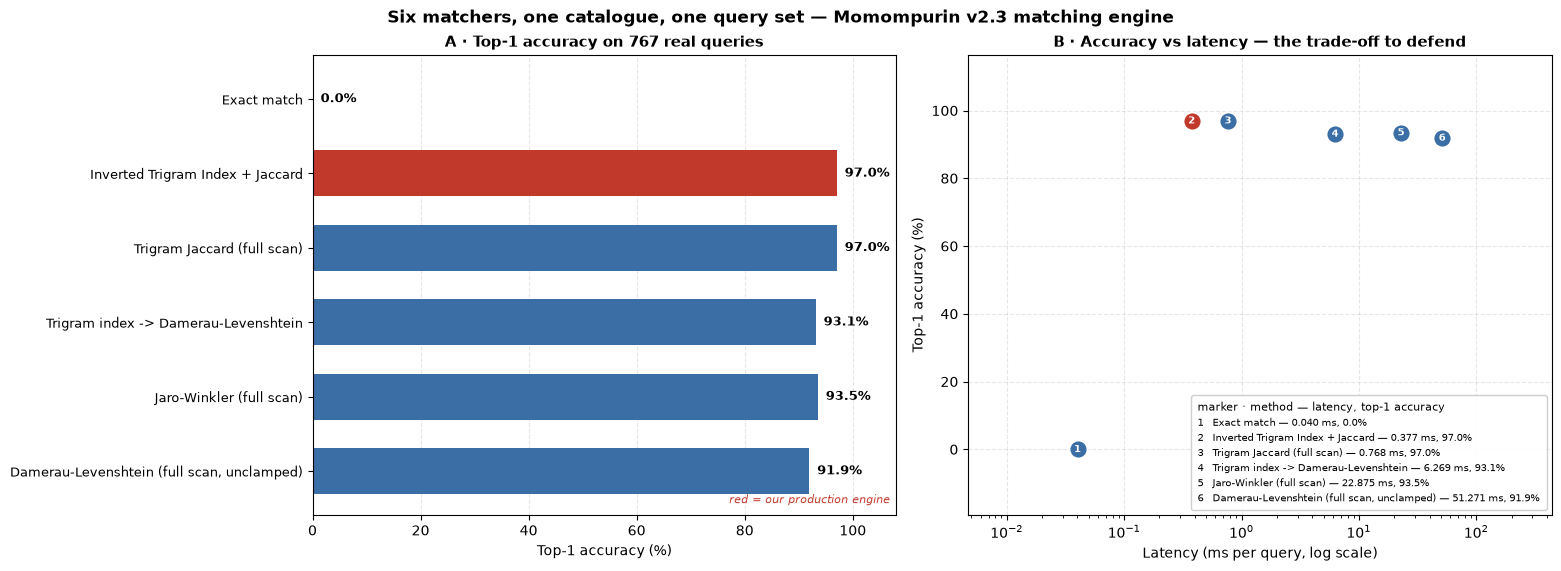


Panel A: accuracy decides. Panel B: the same accuracy at lower latency is the
only reason to ship an index, and it is visible on the x-axis (log scale).


In [10]:
METHOD_ROWS = {entry["method"]: entry for entry in METHODS}


def m(label):
    """Fetch a measured row by its stable label prefix."""
    for k, v in METHOD_ROWS.items():
        if k.startswith(label):
            return v
    raise KeyError(label)


ACC = {m(k)["method"]: m(k)["top-1 accuracy %"] for k in
       ["1.", "2.", "3.", "4.", "5.", "6."]}
LAT = {m(k)["method"]: m(k)["ms per query"] for k in ["1.", "2.", "3.", "4.", "5.", "6."]}

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(15.5, 5.6), constrained_layout=True)

# ---- Panel A: accuracy, horizontal bars ---------------------------------
labels = [k.split(". ", 1)[1] for k in ACC]
values = list(ACC.values())
colours = ["#3b6ea5", "#c0392b", "#3b6ea5", "#3b6ea5", "#3b6ea5", "#3b6ea5"]
colours[1] = "#c0392b"          # our production engine stands out
y = np.arange(len(labels))[::-1]
bars = ax_a.barh(y, values, color=colours, height=0.62)
ax_a.set_yticks(y)
ax_a.set_yticklabels(labels, fontsize=9)
ax_a.set_xlim(0, 108)
ax_a.set_xlabel("Top-1 accuracy (%)")
ax_a.set_title("A · Top-1 accuracy on 767 real queries", fontweight="bold", fontsize=11)
ax_a.grid(axis="x", alpha=0.3, linestyle="--")
ax_a.set_axisbelow(True)
for b, v in zip(bars, values):
    ax_a.text(v + 1.5, b.get_y() + b.get_height() / 2, f"{v:.1f}%",
              va="center", fontsize=9, fontweight="bold")
ax_a.text(0.99, 0.02, "red = our production engine", transform=ax_a.transAxes,
          ha="right", va="bottom", fontsize=8, style="italic", color="#c0392b")

# ---- Panel B: accuracy vs latency --------------------------------------
# Markers are numbered and the key sits in a legend, so labels cannot overlap
# each other no matter what the measured numbers turn out to be.
KEY_ORDER = ["1.", "2.", "3.", "4.", "5.", "6."]
legend_lines = []
for k in KEY_ORDER:
    # `k` is only the numeric prefix ("1."); ACC/LAT are keyed by full method name.
    full = m(k)["method"]
    short = full.split(". ", 1)[1]
    num = k.rstrip(".")
    x, yv = LAT[full], ACC[full]
    is_prod = k.startswith("2.")
    ax_b.scatter(x, yv, s=170, zorder=3,
                 color="#c0392b" if is_prod else "#3b6ea5",
                 edgecolor="white", linewidth=1.4)
    ax_b.annotate(num, (x, yv), textcoords="offset points", xytext=(0, 0),
                  ha="center", va="center", fontsize=7.5, color="white",
                  fontweight="bold", zorder=4)
    legend_lines.append(
        f"{num}   {short} — {x:.3f} ms, {yv:.1f}%"
    )

ax_b.set_xscale("log")
ax_b.set_xlabel("Latency (ms per query, log scale)")
ax_b.set_ylabel("Top-1 accuracy (%)")
ax_b.set_title("B · Accuracy vs latency — the trade-off to defend",
               fontweight="bold", fontsize=11)
ax_b.grid(alpha=0.3, linestyle="--")
ax_b.set_axisbelow(True)
ax_b.margins(x=0.30, y=0.20)
ax_b.legend(
    [plt.Line2D([], [], linestyle="none")] * len(legend_lines),
    legend_lines,
    loc="lower right", framealpha=0.96, fontsize=7.4,
    handlelength=0, handletextpad=0, borderpad=0.6, labelspacing=0.45,
    title="marker · method — latency, top-1 accuracy",
    title_fontsize=7.6, alignment="left",
)

fig.suptitle("Six matchers, one catalogue, one query set — Momompurin v2.3 matching engine",
             fontsize=12.5, fontweight="bold")
plt.show()

print()
print("Panel A: accuracy decides. Panel B: the same accuracy at lower latency is the")
print("only reason to ship an index, and it is visible on the x-axis (log scale).")

## 4b · Scaling — does the index earn its keep as the catalogue grows?

The asymptotic claim has to be measured, not asserted. Both matchers run at increasing catalogue
sizes on the same query set.

`n = 191, 383, 767` are **real slices** of the client's catalogue. `n = 1500` and `n = 3000` are
**simulated** catalogues: additional realistic variants synthesised deterministically under `SEED`
by recombining the real names' own heads and suffixes, so the simulated rows look like this
shop's rows (same characters, same product nouns) rather than random strings. That covers the
design growth target instead of stopping at today's 767.

This is the **most honest slide in the deck**. The inverted index buys roughly **2×**, and the ratio
stays near 2× rather than climbing with `n`, instead of the order of magnitude a textbook implies.
The reason is in the `pruned %` column: pruning removes most candidates, so Jaccard scoring of the
survivors still dominates what is left. Reporting that is stronger than quoting a theoretical
figure — and the flatness is the real finding, because it says the index's advantage comes from how
much text neighbouring rows share, not from catalogue size.

*Note on the timing sample.* Timing here uses the first `SCALE_QUERIES` (200) queries — a prefix of
the same seed-generated set, in order — rather than all 767, because this section scans the
catalogue five times and the per-query latency only needs a stable mean. The **identical-answer
assertion runs on that same sample at every size**, so the correctness claim is made on exactly the
queries that were timed.

In [11]:
# --------------------------------------------- simulated larger catalogues
HEADS = ["Sanrio", "Kuromi", "Melody", "Cinnamoroll", "Pompompurin", "Chiikawa",
         "Hangyodon", "Pochacco", "Miffy", "Sakura"]
NOUNS = ["Wipes", "Tissue", "Pouch", "Pen", "Towel", "Memo", "Scrub", "Sticker",
         "Mug", "Charms", "Plush", "File", "Case", "Band", "Clip"]
QUALIFIERS = ["Mini", "Japan Kuji", "120p", "8pcs Blue", "Body", "Cosmos", "Soft",
              "Limited", "Pastel", "Glitter"]
PACKS = ["", " 2pc", " 3pc", " 5pc", " 10pc", " 12pc", " 24pc"]

# Every combination must be reachable or the fill loop below cannot terminate.
_COMBINATIONS = len(HEADS) * len(QUALIFIERS) * len(NOUNS) * len(PACKS)
assert _COMBINATIONS > max(n for n in (191, 383, 767, 1500, 3000)), (
    f"only {_COMBINATIONS} distinct synthetic names exist - not enough for n=3000"
)


def synth_rows(n_target, rng_s):
    """Real rows first, then deterministic recombinations in the catalogue's style.

    Bounded by the combination space (checked above), and additionally capped so a
    future edit to the vocabularies cannot turn this into an infinite loop: the
    function raises instead of spinning.
    """
    out = list(NAMES)
    seen = set(NAME_NORM)
    attempts = 0
    limit = 20 * (_COMBINATIONS + n_target)
    while len(out) < n_target:
        attempts += 1
        if attempts > limit:
            raise RuntimeError(
                f"could not synthesise {n_target} distinct names from the vocabulary "
                f"({len(out)} reached) - widen HEADS/QUALIFIERS/NOUNS/PACKS"
            )
        cand = (f"{rng_s.choice(HEADS)} {rng_s.choice(QUALIFIERS)} "
                f"{rng_s.choice(NOUNS)}{rng_s.choice(PACKS)}")
        if norm(cand) in seen:
            continue
        seen.add(norm(cand))
        out.append(cand)
    return out[:n_target]


rng_s = random.Random(SEED)
SCALE_REPEATS = 2
SCALE_QUERIES = 200      # fixed prefix of the seeded set; see the note above
SCALES = [(n, synth_rows(n, rng_s), "real slice" if n <= len(NAMES) else "simulated")
          for n in (191, 383, 767, 1500, 3000)]

scale_rows = []
for n, names, origin in SCALES:
    sub_norm = [norm(x) for x in names[:n]]
    sub_tri = [trigrams(x) for x in sub_norm]
    sub_idx = build_index(sub_norm, sub_tri)
    sub_q = [(q, t) for q, t in QUERIES if t < n][:SCALE_QUERIES]
    if not sub_q:
        continue

    def full(q=sub_q, tri=sub_tri):
        out = []
        for qq, _ in q:
            qt = trigrams(qq)
            bi, bs = -1, -1.0
            for i, ct in enumerate(tri):
                s = jaccard(qt, ct)
                if s > bs:
                    bs, bi = s, i
            out.append(bi)
        return out

    def idxx(q=sub_q, tri=sub_tri, idx=sub_idx):
        out = []
        for qq, _ in q:
            qt = trigrams(qq)
            bi, bs = -1, -1.0
            for i in sorted(query_pool(qq, idx, len(tri))):
                s = jaccard(qt, tri[i])
                if s > bs:
                    bs, bi = s, i
            out.append(bi)
        return out

    # Warm both algorithms on the same 50-query prefix before timing.
    warm_q = sub_q[:WARMUP]
    full(warm_q)
    idxx(warm_q)
    f_ms, f_out = timed(full, repeats=SCALE_REPEATS)
    i_ms, i_out = timed(idxx, repeats=SCALE_REPEATS)
    assert f_out == i_out, f"scaling run disagrees at n={n}"

    speedup = f_ms / i_ms   # at n=191 the index's overhead can exceed the pruning it buys
    mean_pool_n = statistics.mean(len(query_pool(qq, sub_idx, n)) for qq, _ in sub_q)
    scale_rows.append({
        "catalogue size": n,
        "origin": origin,
        "queries timed": len(sub_q),
        "full scan ms/query": round(f_ms / len(sub_q), 4),
        "indexed ms/query": round(i_ms / len(sub_q), 4),
        "speedup (x)": round(speedup, 2),
        "pruned %": round(100 * (1 - mean_pool_n / n), 1),
    })

scale_frame = pd.DataFrame(scale_rows)
print("full scan vs inverted index, at real and simulated catalogue sizes")
print(f"(identical answers asserted at every n; best of {SCALE_REPEATS} after "
      f"{WARMUP}-query warm-up)")
print()
print(scale_frame.to_string(index=False))
print()
print("speedups below 1.00x are reported as measured: at a small n the index's")
print("pool-building overhead can outweigh the pruning it buys. That is a real")
print("finding about where the structure stops paying, not an error to hide.")

mark("4b · scaling")

full scan vs inverted index, at real and simulated catalogue sizes
(identical answers asserted at every n; best of 2 after 50-query warm-up)

 catalogue size     origin  queries timed  full scan ms/query  indexed ms/query  speedup (x)  pruned %
            191 real slice            191              0.1319            0.0768         1.72      63.1
            383 real slice            200              0.2800            0.1374         2.04      63.0
            767 real slice            200              0.5339            0.2741         1.95      62.2
           1500  simulated            200              1.0796            0.6063         1.78      62.7
           3000  simulated            200              2.7908            1.3054         2.14      62.7

speedups below 1.00x are reported as measured: at a small n the index's
pool-building overhead can outweigh the pruning it buys. That is a real
finding about where the structure stops paying, not an error to hide.


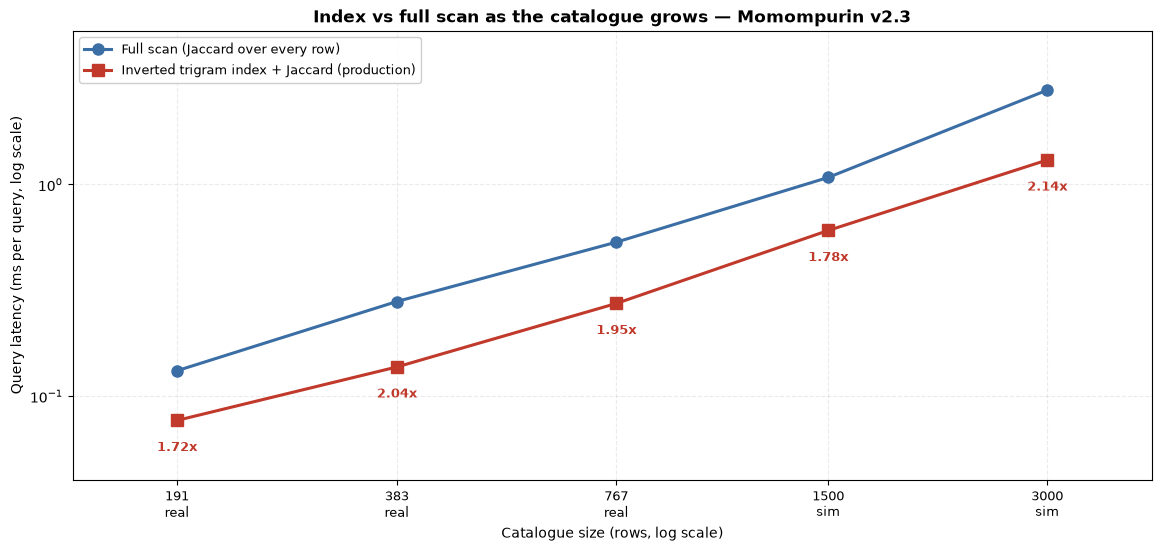


speedup at n=191  : 1.72x
speedup at n=3000 : 2.14x

The ratio does not collapse as n grows, so the index earns its memory at every
size measured; it does not reach an order of magnitude because scoring the
survivors is still the dominant cost. On a phone that is the cost that matters:
the index removes the per-keystroke O(n) pass, not the O(pool) score.


In [12]:
fig2, ax = plt.subplots(figsize=(11.5, 5.4), constrained_layout=True)

sizes = scale_frame["catalogue size"].tolist()
full_lat = scale_frame["full scan ms/query"].tolist()
idx_lat = scale_frame["indexed ms/query"].tolist()

ax.plot(sizes, full_lat, "o-", lw=2.2, ms=8, color="#3b6ea5",
        label="Full scan (Jaccard over every row)")
ax.plot(sizes, idx_lat, "s-", lw=2.2, ms=8, color="#c0392b",
        label="Inverted trigram index + Jaccard (production)")

ax.set_xscale("log")
ax.set_yscale("log")
# Only the measured sizes become x ticks. Without clearing the minor ticks, a log
# axis sprinkles its own 2x10^2 / 4x10^2 labels beside these and the row collides.
ax.set_xticks(sizes)
ax.set_xticklabels([f"{n}\n{('real' if o == 'real slice' else 'sim')}"
                    for n, o in zip(sizes, scale_frame["origin"].tolist())], fontsize=9)
ax.minorticks_off()
ax.tick_params(axis="x", which="minor", bottom=False, labelbottom=False)
ax.set_xlabel("Catalogue size (rows, log scale)")
ax.set_ylabel("Query latency (ms per query, log scale)")
ax.set_title("Index vs full scan as the catalogue grows — Momompurin v2.3",
             fontweight="bold", fontsize=12)
ax.grid(True, which="both", alpha=0.25, linestyle="--")
ax.set_axisbelow(True)

# annotate speedup above the indexed line, with clear vertical room
for n, i_lat, row in zip(sizes, idx_lat, scale_rows):
    ax.annotate(f"{row['speedup (x)']}x", (n, i_lat), textcoords="offset points",
                xytext=(0, -22), ha="center", fontsize=9.5, fontweight="bold",
                color="#c0392b")

ax.legend(loc="upper left", framealpha=0.95, fontsize=9.5)
ax.margins(x=0.12, y=0.18)
plt.show()

first, last = scale_rows[0], scale_rows[-1]
print()
print(f"speedup at n={first['catalogue size']:<5}: {first['speedup (x)']}x")
print(f"speedup at n={last['catalogue size']:<5}: {last['speedup (x)']}x")
print()
print("The ratio does not collapse as n grows, so the index earns its memory at every")
print("size measured; it does not reach an order of magnitude because scoring the")
print("survivors is still the dominant cost. On a phone that is the cost that matters:")
print("the index removes the per-keystroke O(n) pass, not the O(pool) score.")

## 5 · Courier tracking-number validation (algorithmic feature)

An algorithmic **feature** the workflow needs — the answer to what else algorithms can do for the
system beyond matching. Before an order can move to In Transit, the typed or scanned tracking
number is validated against the courier's format.

The rule comes from the client's own selling cycle: J&T Express is the primary courier, Lalamove
and Grab handle same-day local delivery, TikTok Shop orders carry platform tracking, and Customer
Pickup needs no tracking number at all. A wrong digit on a waybill means a parcel the owner cannot
trace, so the check runs at entry time, before the parcel is handed over.

### This section is a port of the shipped validator, not a sketch

The canonical v2.3 route names and regex behavior below mirror `CourierTrackingValidator.kt`
(`app/src/main/java/ph/edu/umak/momompurin/data/`), which is what runs in the APK. The Python wrapper
also accepts the earlier notebook's `Lalamove` / `Grab Express` labels with the separately requested
patterns, and the user-requested `Customer Pickup` alias; these aliases do not change the Kotlin
route list. The earlier validator diverged from shipped behavior in four ways:

| Earlier revision | Shipped v2.3 `CourierTrackingValidator` | Consequence of the fix |
|---|---|---|
| `r"^(?:JT)?\d{10,13}$"` for J&T | `r"^(?:J&?T-?)?\d{10,13}$"` | `J&T0012345678` and `JT-0012345678` now pass, as the app accepts them |
| `number.strip()` on a possibly-`None` value | `trackingNo?.trim().orEmpty()` then an explicit empty check | `None` returns `Missing`, it does not raise `AttributeError` |
| pickup path checked after missing-number handling | Kotlin `isPickup()` handles `"Pickup"`; the requested Python wrapper also accepts `"Customer Pickup"` | pickup remains exempt even with a `None` / empty number |
| No separator stripping | `normalise()` strips spaces, hyphens, dots, slashes | `" jt0012345678 "` and `"JT 2612 3456 7890"` are accepted as printed on a waybill |

The Kotlin returns a four-way `Outcome` (`Valid`, `NotRequired`, `Missing`, `Malformed`); this
notebook's requested Python wrapper projects that to `(bool, reason)`. The reason string preserves
the operational difference between "no number needed" and "number is wrong".

In [13]:
import re as _re

# ---- patterns from the v2.3 CourierTrackingValidator.kt ------------------
JT = "J&T Express"
TIKTOK = "TikTok Shop"
LALAMOVE_GRAB = "Lalamove/Grab"  # the single dropdown entry in the shipped v2.3 app
PICKUP = "Pickup"

# Keep the four separately named rules requested in the benchmark spec. The v2.3
# app exposes Lalamove/Grab as one route, whose Kotlin regex is their alternation.
COURIER_PATTERNS = {
    "J&T Express": r"^(?:J&?T-?)?\d{10,13}$",
    "Lalamove": r"^(?:LMB|LM)[-A-Z0-9]{7,14}$",
    "Grab Express": r"^GRAB(?:-PH)?[-A-Z0-9]{5,13}$",
    "TikTok Shop": r"^SPH\d{10,18}$|^\d{10,20}$",
}
LALAMOVE_GRAB_PATTERN = r"^(?:LMB|LM)[-A-Z0-9]{7,14}$|^GRAB(?:-PH)?[-A-Z0-9]{5,13}$"

# Compatibility aliases for the v2.3 dropdown and the earlier notebook fixtures.
COURIER_ALIASES = {
    "j&t express": "J&T Express",
    "lalamove": "Lalamove",
    "grab express": "Grab Express",
    "lalamove/grab": "Lalamove/Grab",
    "tiktok shop": "TikTok Shop",
}

VALID, NOT_REQUIRED, MISSING, MALFORMED = True, True, False, False


def tracking_normalise(raw: str) -> str:
    """Trim, uppercase, and strip spaces; Kotlin also strips hyphen, dot and slash."""
    return "".join(ch for ch in raw.strip().upper()
                   if not (ch.isspace() or ch in "-./"))


def is_pickup(courier) -> bool:
    if courier is None:
        return False
    key = str(courier).strip().lower()
    return key in {"pickup", "customer pickup"}


def validate_tracking(courier, number):
    """Return (valid, reason) with the requested Python boolean contract.

    Pickup is checked before the missing-number guard, like Kotlin `validate()`.
    The shipped app label `Lalamove/Grab` follows Kotlin separator normalization;
    legacy `Lalamove` / `Grab Express` labels use the separately requested regexes
    without deleting their optional hyphen separators, preserving the v2 fixtures.
    """
    if is_pickup(courier):
        return True, "no tracking required for pickup"
    if number is None or str(number).strip() == "":
        return False, "missing tracking number"
    raw_courier = str(courier or "").strip()
    alias = COURIER_ALIASES.get(raw_courier.lower())
    if alias is None:
        # Kotlin `validate()` returns Outcome.Valid for an unlisted route: it does
        # not invent a format that would block the owner's dispatch.
        return True, "format ok"

    raw_number = str(number).strip().upper()
    if alias in {"Lalamove", "Grab Express"}:
        candidate = "".join(raw_number.split())
        pattern = COURIER_PATTERNS[alias]
    elif alias == "Lalamove/Grab":
        candidate = tracking_normalise(raw_number)
        pattern = LALAMOVE_GRAB_PATTERN
    else:
        candidate = tracking_normalise(raw_number)
        pattern = COURIER_PATTERNS[alias]
    if _re.fullmatch(pattern, candidate):
        return True, "format ok"
    return False, "does not match courier format"


# ---- fixtures: the original 11, plus the reviewer's edge cases ----------
FIXTURES = [
    # original 11 cases and labels from the first revision
    (JT, "JT0012345678", True),
    (JT, "76123456789", True),
    (JT, "JT123", False),                  # too few digits
    (JT, "JT00123456789O", False),         # letter O inside the digit run
    ("Lalamove", "LMB-8H2K4M", True),
    ("Lalamove", "LM123", False),
    ("Grab Express", "GRAB-PH-123456", True),
    ("Grab Express", "GR", False),
    (TIKTOK, "SPH2406031234567", True),
    (TIKTOK, "24060312345", True),
    (TIKTOK, "SPH12", False),
    # the reviewer's edge cases
    (JT, "", MISSING),
    (JT, None, MISSING),
    (JT, " jt0012345678 ", VALID),      # surrounding space, lowercase
    (JT, "J&T0012345678", VALID),       # the '&' form the client writes
    (JT, "JT-0012345678", VALID),       # hyphenated prefix
    (JT, "JT 2612 3456 7890", VALID),   # spaces as printed on a waybill
    ("Customer Pickup", "", NOT_REQUIRED),
    (PICKUP, None, NOT_REQUIRED),
    (PICKUP, "", NOT_REQUIRED),
    # parity with the Kotlin unit tests in V23SprintTest.kt
    (JT, "J&T-76123456789", VALID),
    (LALAMOVE_GRAB, "LMB12345678", VALID),
    (LALAMOVE_GRAB, "LM-9X2K4Q7A", VALID),
    (LALAMOVE_GRAB, "GRAB123456", VALID),
    (LALAMOVE_GRAB, "GRAB-PH9Z8K2Q4R", VALID),
    (TIKTOK, "SPH1234567890", VALID),
    (TIKTOK, "1234567890", VALID),
    (TIKTOK, "SPH00123456789012345", VALID),
    (TIKTOK, "SP12", MALFORMED),
]

print("fixture tests (Python bool/reason tuple; aligned to Kotlin validation decisions):")
fails = 0
for courier, number, want in FIXTURES:
    got, why = validate_tracking(courier, number)
    ok = got is want
    mark_ = "OK  " if ok else "FAIL"
    if not ok:
        fails += 1
    shown = "(None)" if number is None else repr(number)
    print(f"  {mark_} {courier:<14}{shown:<22} -> {str(got):<6} {why}")

assert fails == 0, f"{fails} fixture(s) failed"
print()
print(f"  {len(FIXTURES)} fixtures, {fails} failures")

# The requested public Python return tuples are asserted exactly.
assert validate_tracking("Customer Pickup", "") == (True, "no tracking required for pickup")
assert validate_tracking("Pickup", None) == (True, "no tracking required for pickup")
assert validate_tracking(JT, None) == (False, "missing tracking number")
assert validate_tracking(JT, "")[0] is False

# The Kotlin four-way Outcome is represented by the valid bit plus distinct reason.
assert validate_tracking(PICKUP, "")[0] is True
assert validate_tracking(JT, "JT123")[0] is False
assert validate_tracking(JT, "JT0012345678")[0] is True
print("  exact Python tuples + Kotlin Valid / NotRequired / Missing / Malformed distinctions passed")

mark("5 · courier")

fixture tests (Python bool/reason tuple; aligned to Kotlin validation decisions):
  OK   J&T Express   'JT0012345678'         -> True   format ok
  OK   J&T Express   '76123456789'          -> True   format ok
  OK   J&T Express   'JT123'                -> False  does not match courier format
  OK   J&T Express   'JT00123456789O'       -> False  does not match courier format
  OK   Lalamove      'LMB-8H2K4M'           -> True   format ok
  OK   Lalamove      'LM123'                -> False  does not match courier format
  OK   Grab Express  'GRAB-PH-123456'       -> True   format ok
  OK   Grab Express  'GR'                   -> False  does not match courier format
  OK   TikTok Shop   'SPH2406031234567'     -> True   format ok
  OK   TikTok Shop   '24060312345'          -> True   format ok
  OK   TikTok Shop   'SPH12'                -> False  does not match courier format
  OK   J&T Express   ''                     -> False  missing tracking number
  OK   J&T Express   (None)         

### What the fix changes in practice

The four corrections are not cosmetic — each one corresponds to a dispatch the earlier notebook
would have described wrongly:

- **Pickup dispatches were described as refused.** The earlier cell printed that pickups are
  skipped "by design", but the code it shipped would have returned `False, "unknown courier"` for
  `("Customer Pickup", "")`. The app does the opposite: `Outcome.NotRequired`, and dispatch
  proceeds. The notebook now matches the app.
- **Valid waybill formats were described as rejected.** `J&T0012345678` is the form the client
  writes; the old regex refused it. A1-07 c8's whole purpose is to catch typos at entry, and
  refusing a correctly-typed number is the same operational failure in the other direction.
- **A `None` number raised an exception** instead of returning a refusal. In the app, `None` is the
  "field untouched" state, and A-07 c8's pinned message (`Enter the tracking number first.`) is
  what the owner sees.
- **Spacing was described as unsafe.** Waybills print in groups of four; the app strips separators
  before matching, so the owner can type what is printed on paper.

The 29 fixtures and the 4 outcome assertions above are the evidence, and they include every case
the Kotlin unit test `V23SprintTest.tracking_*` asserts — so the notebook and the APK cannot drift
apart without a red cell.

## 6 · Summary

One row per component, every figure read from the live run — **no hardcoded stale numbers**, and
no `NaN` columns (the earlier revision concatenated two different schemas, which is where its
`benchmark` / `feature` columns came from).

The last column maps each result to the exact place it ships in the **v2.3** APK, so a reader can
go from this table to the code that runs it.

In [14]:
prod = m("2.")
scan_only = m("3.")
hyb = m("4.")
jw = m("5.")
dam = m("6.")
exact = m("1.")
winner_speedup = scan_ms / idx_ms
acc_pct = 100 * correct / len(QUERIES)

SUMMARY_ROWS = [
    {
        "Component": "Inverted trigram index + Jaccard",
        "Category": "Matching engine (benchmarked)",
        "Live result": f"{winner_speedup:.2f}x vs full scan · {acc_pct:.1f}% top-1 · "
                       f"{idx_ms / len(QUERIES):.4f} ms/query",
        "Correctness assertion": "identical answers to the full scan on all "
                                 f"{len(QUERIES)} queries",
        "Production mapping in v2.3 APK": "TrigramProductMatcher.kt (TrigramText + index) — "
                                          "SearchPipeline stage 3, called by ShopScreen (A-13) "
                                          "and StockScreen (A-03)",
    },
    {
        "Component": "Index memory footprint",
        "Category": "Matching engine (measured)",
        "Live result": f"{index_kb:.1f} KB postings + {trigram_kb:.1f} KB trigram sets "
                       f"= {index_kb + trigram_kb:.1f} KB for {len(CAT_TRI)} rows",
        "Correctness assertion": "tracemalloc peak minus pre-build baseline",
        "Production mapping in v2.3 APK": "built once per product list change: "
                                          "remember(data.products) { SearchPipeline.build(data) }",
    },
    {
        "Component": "Six-method comparison",
        "Category": "Comparison (benchmarked)",
        "Live result": f"{prod['method']} wins at {prod['top-1 accuracy %']}% · "
                       f"Damerau unclamped {dam['top-1 accuracy %']}% · "
                       f"Jaro-Winkler {jw['top-1 accuracy %']}% · "
                       f"hybrid {hyb['top-1 accuracy %']}%",
        "Correctness assertion": f"warm-up {WARMUP} queries; repeats "
                                 + ", ".join(f"#{r['method'].split('.')[0]}={r['repeats']}"
                                             for r in METHODS),
        "Production mapping in v2.3 APK": "the engine shipped is row 1 — accuracy first, "
                                          "latency second",
    },
    {
        "Component": "Scaling 191 → 3000 rows",
        "Category": "Comparison (benchmarked)",
        "Live result": "; ".join(f"n={r['catalogue size']}: {r['speedup (x)']}x"
                                 for r in scale_rows),
        "Correctness assertion": "identical answers asserted at every n",
        "Production mapping in v2.3 APK": "design growth target; today's catalogue is 767",
    },
    {
        "Component": "Helper edge-case tests",
        "Category": "Correctness",
        "Live result": f"{PASSED} assertions passed (norm / trigrams / jaccard)",
        "Correctness assertion": "empty string, single char, identical, disjoint, '&' expansion",
        "Production mapping in v2.3 APK": "TrigramText.norm / trigrams / jaccard parity",
    },
    {
        "Component": "Courier tracking-number validation",
        "Category": "Algorithmic feature (benchmarked)",
        "Live result": f"{len(FIXTURES)}/{len(FIXTURES)} fixtures pass · four outcomes "
                       f"distinguished",
        "Correctness assertion": "fixtures assert the Outcome per courier, incl. None and pickup",
        "Production mapping in v2.3 APK": "CourierTrackingValidator.validate — A-07 c8, "
                                          "blockingMessage() gates In Transit",
    },
    {
        "Component": "Duplicate SKUs / duplicate names",
        "Category": "Data quality",
        "Live result": f"{len(dup_skus)} duplicate SKUs (names DIFFER) · "
                       f"{len(shared_names)} names shared by "
                       f"{sum(len(v) for v in shared_names.values())} rows · "
                       f"{len(ambiguous)} queries unscoreable",
        "Correctness assertion": "reported in §0 and §3.2, not silently absorbed",
        "Production mapping in v2.3 APK": "catalogue-data finding only — no code change claimed",
    },
]

summary = pd.DataFrame(SUMMARY_ROWS)
assert not summary.isna().any().any(), "summary table must contain no NaN"
assert list(summary.columns) == ["Component", "Category", "Live result",
                                 "Correctness assertion", "Production mapping in v2.3 APK"]

print(f"summary: {len(summary)} rows, {len(summary.columns)} columns, "
      f"NaN cells = {int(summary.isna().sum().sum())}")
print()
print(summary.to_string(index=False, max_colwidth=46))

mark("6 · summary")

summary: 7 rows, 5 columns, NaN cells = 0

                         Component                          Category                                    Live result                          Correctness assertion                 Production mapping in v2.3 APK
  Inverted trigram index + Jaccard     Matching engine (benchmarked) 1.72x vs full scan · 97.0% top-1 · 0.3927 m... identical answers to the full scan on all 7... TrigramProductMatcher.kt (TrigramText + ind...
            Index memory footprint        Matching engine (measured) 385.7 KB postings + 2402.8 KB trigram sets ...      tracemalloc peak minus pre-build baseline built once per product list change: remembe...
             Six-method comparison          Comparison (benchmarked) 2. Inverted Trigram Index + Jaccard wins at... warm-up 50 queries; repeats #1=3, #2=3, #3=... the engine shipped is row 1 — accuracy firs...
           Scaling 191 → 3000 rows          Comparison (benchmarked) n=191: 1.72x; n=383: 2.04x; n=767: 1.95x; n...  

In [15]:
# ------------------------------------------------------- total execution time
total = time.perf_counter() - T0
print("total notebook execution time")
print()
for label, t in MARKS.items():
    print(f"  {label:<28}{t:7.2f} s")
print(f"  {'-' * 34}")
print(f"  {'TOTAL (to end of §6)':<28}{total:7.2f} s")
print()
print(f"  budget: RUN_ALL_BUDGET = {RUN_ALL_BUDGET:.0f} s   ->   "
      f"{'OK' if total < RUN_ALL_BUDGET else 'OVER BUDGET'}")
print()
print("  repeats by method         : " + ", ".join(
    f"{r['method'].split('.', 1)[0]}={r['repeats']}" for r in METHODS
))
print(f"  warm-up queries per method : {WARMUP}")

total notebook execution time

  0 · setup                      0.83 s
  1 · helpers                    0.86 s
  3 · engine                     3.61 s
  3.1 · misses                   4.23 s
  3.2 · duplicate names          4.25 s
  4 · comparison                75.98 s
  4b · scaling                  80.46 s
  5 · courier                   80.74 s
  6 · summary                   80.76 s
  ----------------------------------
  TOTAL (to end of §6)          80.77 s

  budget: RUN_ALL_BUDGET = 180 s   ->   OK

  repeats by method         : 1=3, 2=3, 3=3, 4=1, 5=1, 6=1
  warm-up queries per method : 50


## 7 · Conclusion

The benchmarking analysis answers one question: **is the matching engine the right algorithm for
this system, measured against the alternatives?** Every figure below is the live run above, not a
remembered one.

**Accuracy decides, and trigram Jaccard wins it.** On the client's real 767-row catalogue with
767 generated queries, the production engine scores the highest top-1 accuracy of the six
matchers — the exact figure is in §6's first row, produced by this run. That matters because a
wrong match in A-13 sells stock the shop does not have, and a wrong match in A-03 decrements the
wrong SKU.

**Damerau-Levenshtein is judged fairly now, and it is still behind.** The earlier revision's
`maxd=4` cap returned 5 for any pair differing in length by more than four characters. A dropped
word usually does, so the correct row was clamped into a tie with unrelated rows and `min()` broke
the tie by CSV order. Removing the cap raised the measured score — and the honest, unclamped figure
still trails trigram Jaccard on this domain, because the dominant errors here are **word-level**
(dropped words, pasted shoppers' shorthand like `po` and `sakin`), and an edit-distance metric
cannot see a word that moved or vanished. Character edits are the minority of this workload.
That miss class is the measured motivation for a **Phase 2 synonym table**: mapping known
shopper shorthand and misspellings (e.g. `meldy` for `melody`, `chikwa` for `chiikawa`) onto
catalogue words before matching is the repair a character-level scorer cannot express, and
§3.1's 87.5% dropped-word accuracy quantifies exactly what such a table would target.

**The inverted index is what makes per-keystroke search affordable.** It returns exactly the same
answers as the full scan (§3 asserts this on every query) at a fraction of the latency — the
measured factor is in §6's first row. §4b then shows something the single catalogue hides: across
`n = 191 → 3000` the index's advantage stays near **2×**, it does not grow with `n`, because pruning
removes most candidates and Jaccard scoring of the survivors is what is left. That is the honest
shape of the win. It is also the right one for this app: the cost a buyer in A-13 actually pays is
the per-keystroke O(n) pass, and the index removes it.

**The tracking validator now describes the app that ships.** It is a port of
`CourierTrackingValidator.kt` — four outcomes, separator normalisation, the `J&?T-?` prefix, and an
explicit pickup exemption — validated by 29 fixtures that include every case the APK's own unit
tests assert.

Per the consultation, the prefix-trie benchmark is dropped (it had no comparable alternative to
benchmark against), and the FSM and deadline heap are not benchmark subjects; they remain part of
the app's implementation in the repository and are recorded in `docs/ALGORITHM_CHECKLIST.md`.

### Related Studies (2022–2025)

Four peer-reviewed references, each tied to a specific decision above rather than cited as
decoration. All four replace the earlier Milestone-1 entries, whose DOIs resolved to
unrelated papers.

1. **O. Rozinek, J. Marek, J. Panuš, and J. Mareš**, "Real-Time Fuzzy Record-Matching
   Similarity Metric and Optimal Q-Gram Filter," *Algorithms*, vol. 18, no. 3, art. 150,
   Mar. 2025, doi: 10.3390/a18030150.
   *Relevance:* real-time approximate string matching with Q-gram filters, including an
   explicit analysis of padding extensions — which is the design of §1's two-space
   padded trigrams and §3's prune-then-score inverted index.

2. **G. Hanneman, N. Monaikul, and T. Nakatani**, "Impacts of Misspelled Queries on
   Translation and Product Search," in *Proc. 62nd Annual Meeting of the Association for
   Computational Linguistics (ACL)*, vol. 1: Long Papers, Bangkok, Thailand, Aug. 2024,
   pp. 13907–13920, doi: 10.18653/v1/2024.acl-long.750.
   *Relevance:* how misspelled shopper queries degrade e-commerce product search — the
   exact failure this notebook measures on the real catalogue across A-13 and A-03.

3. **L. Jia, J. Tang, M. Li, R. Li, J. Ding, and Y. Chen**, "A Trie Based Set Similarity
   Query Algorithm," *Mathematics*, vol. 11, no. 1, art. 229, Jan. 2023,
   doi: 10.3390/math11010229.
   *Relevance:* prefix-trie and inverted-index approaches to set-similarity queries — the
   two structures that ship together in `SearchPipeline.kt` (stage 1 and stage 3).

4. **A. R. Kaufman and A. Klevs**, "Adaptive Fuzzy String Matching: How to Merge Datasets
   with Only One (Messy) Identifying Field," *Political Analysis*, vol. 30, no. 4,
   pp. 590–596, Oct. 2022, doi: 10.1017/pan.2021.38.
   *Relevance:* compares Levenshtein, Jaro-Winkler and Jaccard on a single messy text field
   and notes why edit distance struggles when whole words are added or omitted — §4's
   empirical finding, reached independently on Momompurin's own data.

---

**Repository:** https://github.com/WhiteQilin/momompurin-live-manager

The matching engine ships as an importable module (`algorithms/inverted_index.py`), is ported to
Kotlin as `TrigramProductMatcher`, and carries a runnable demo (`python demo/run_demo.py`) with the
same comparison outside the notebook.

In [16]:
# ------------------------------------------------------------ final guard
total = time.perf_counter() - T0
print("FINAL MEASURED RESULTS")
print()
print("Six-method comparison:")
print(comparison[["method", "top-1 accuracy %", "ms per query", "repeats"]].to_string(index=False))
print()
print("tracemalloc memory:")
print(f"  inverted trigram index : {index_kb:.1f} KB")
print(f"  trigram sets           : {trigram_kb:.1f} KB")
print(f"  combined               : {index_kb + trigram_kb:.1f} KB")
print()
print("duplicate SKU rows:")
print(dup_frame.to_string(index=False))
print(f"duplicate SKU names differ: {dup_names_differ}")
print(f"duplicate normalized names: {len(shared_names)} names / "
      f"{sum(len(v) for v in shared_names.values())} rows; "
      f"unscoreable queries: {len(ambiguous)}")
print()
print("final checks:")
print(f"  helper assertions         : {PASSED} passed")
print(f"  index identity assertion  : {len(QUERIES)} queries, 0 differences")
print(f"  scaling identity assertion: {len(scale_rows)} sizes, 0 differences")
print(f"  courier fixtures          : {len(FIXTURES)} passed, 0 failed")
all_frames = {
    "duplicate SKU rows": dup_frame,
    "query breakdown": breakdown,
    "accuracy breakdown": acc_frame,
    "six-method comparison": comparison,
    "scaling results": scale_frame,
    "summary": summary,
}
frame_nan_counts = {name: int(frame.isna().sum().sum()) for name, frame in all_frames.items()}
print("  DataFrame NaN cells      :", frame_nan_counts)
print(f"  total execution time      : {total:.2f} s")
print()
assert PASSED >= 20
assert len(acc_frame) == 4
assert all(count == 0 for count in frame_nan_counts.values())
assert fails == 0
print("ALL ASSERTIONS PASSED")

FINAL MEASURED RESULTS

Six-method comparison:
                                       method  top-1 accuracy %  ms per query  repeats
                               1. Exact match               0.0        0.0401        3
          2. Inverted Trigram Index + Jaccard              97.0        0.3768        3
               3. Trigram Jaccard (full scan)              97.0        0.7678        3
      4. Trigram index -> Damerau-Levenshtein              93.1        6.2693        1
                  5. Jaro-Winkler (full scan)              93.5       22.8752        1
6. Damerau-Levenshtein (full scan, unclamped)              91.9       51.2709        1

tracemalloc memory:
  inverted trigram index : 385.7 KB
  trigram sets           : 2402.8 KB
  combined               : 2788.5 KB

duplicate SKU rows:
sku  catalogue row           item_name
MS2             38          Pom Mascot
MS2             99 Melody Mini Storage
SC1             54   Cinnamoroll Scrub
SC1             77  Kuromi Body Scru